# Dimensionality Reduction — Knesset 25 Elections
### Demonstration Notebook

This notebook demonstrates the functions implemented in `dimensionality_reduction.py`
on the **Knesset 25 elections** ballot-box dataset (`knesset_25.xlsx`). Each row of the
raw dataset represents a single ballot box (קלפי), with columns for the city name,
the ballot box code, and the number of votes each party received at that ballot box.

**Contents**
1. Load the dataset
2. Group & aggregate data by city
3. Remove sparse (low-vote) party columns
4. Dimensionality reduction with PCA (implemented from scratch)
5. Visualize the reduced data — cities, parties, and Jerusalem vs. Tel Aviv-Yafo


## 1. Load the Dataset

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from dimensionality_reduction import (
    load_data,
    group_and_aggregate_data,
    remove_sparse_columns,
    dimensionality_reduction,
)

df = load_data("knesset_25.xlsx")
print(df.shape)
df[["city_name", "ballot_code", "party_likud", "party_yesh_atid", "party_shas"]].head()


(12545, 42)


,city_name,ballot_code,party_likud,party_yesh_atid,party_shas
0,אבו גווייעד שבט,3.1,9,0,0
1,אבו גווייעד שבט,3.2,1,0,0
2,אבו גווייעד שבט,3.3,0,1,2
3,אבו גווייעד שבט,3.4,2,0,2
4,אבו גוש,1.1,11,5,0


Each row is one ballot box. There are 12,545 ballot boxes across 1,216 localities and
40 party-vote columns, plus `city_name` and `ballot_code`.

## 2. Group and Aggregate Data

We aggregate the ballot-box level data up to the **city level** by summing the votes
each party received across all ballot boxes in that city. We drop `ballot_code` first
since summing ballot-box codes is not meaningful.

In [3]:
df_parties = df.drop(columns=["ballot_code"])
agg = group_and_aggregate_data(df_parties, group_by_column="city_name", agg_func="sum")
print(agg.shape)
agg[["city_name", "party_likud", "party_yesh_atid", "party_shas", "party_avoda"]].head()


(1216, 41)


,city_name,party_likud,party_yesh_atid,party_shas,party_avoda
0,אבו גווייעד שבט,12,1,4,1
1,אבו גוש,208,26,4,14
2,אבו סנאן,405,163,12,34
3,אבו עבדון שבט,0,0,0,0
4,אבו קורינאת שבט,9,4,3,5


### Total votes each party received in each city
This is exactly the `agg` table above — every column (besides `city_name`) is a party, and every row is a city with that party's total vote count.

### Total votes the 5 most popular parties received in each city
First we find the 5 parties with the most votes **nationwide**, then show their vote counts per city.

In [4]:
party_cols = [c for c in agg.columns if c != "city_name"]
party_totals = agg[party_cols].sum().sort_values(ascending=False)
top5_parties = party_totals.head(5).index.tolist()
print("Top 5 parties (nationwide):", top5_parties)

agg[["city_name"] + top5_parties].head(8)


Top 5 parties (nationwide): ['party_likud', 'party_yesh_atid', 'party_tet', 'party_kahol_lavan', 'party_shas']


,city_name,party_likud,party_yesh_atid,party_tet,party_kahol_lavan,party_shas
0,אבו גווייעד שבט,12,1,0,5,4
1,אבו גוש,208,26,13,8,4
2,אבו סנאן,405,163,6,401,12
3,אבו עבדון שבט,0,0,0,0,0
4,אבו קורינאת שבט,9,4,0,0,3
5,אבו קרינאת יישוב,2,12,0,1,0
6,אבו רובייעה שבט,27,9,1,12,6
7,אבו רוקייק שבט,9,5,17,2,3


### Total votes the 5 most popular parties received in the 10 cities with the highest voter turnout

The dataset does not include a separate "registered voters" column, so we use **total
votes cast** in a city as a proxy for turnout volume, and sort cities from highest to
lowest. Note `מעטפות חיצוניות` ("external envelopes") is a special aggregated category
for double-envelope/absentee ballots rather than an actual city — it appears first
because of its scale, and we keep it here for completeness but exclude it later in the
spatial (city-clustering) visualizations since it doesn't correspond to a real place.

In [5]:
agg_with_turnout = agg.copy()
agg_with_turnout["total_votes"] = agg_with_turnout[party_cols].sum(axis=1)

top10_turnout = agg_with_turnout.sort_values("total_votes", ascending=False).head(10)
top10_turnout[["city_name", "total_votes"] + top5_parties].reset_index(drop=True)


,city_name,total_votes,party_likud,party_yesh_atid,party_tet,party_kahol_lavan,party_shas
0,מעטפות חיצוניות,458714,107885,77681,70887,48847,31378
1,תל אביב יפו,265796,45221,87227,11968,29291,11442
2,ירושלים,264700,50582,19773,37635,13905,48470
3,חיפה,139764,29260,36777,8792,14168,4425
4,ראשון לציון,139546,45144,35166,13561,19255,6936
5,פתח תקווה,133437,37935,26397,18368,14176,11932
6,אשדוד,116294,33635,14868,10459,7678,18254
7,נתניה,113043,40142,19747,12871,9552,13767
8,חולון,101811,35294,20947,10380,11844,10719
9,באר שבע,100204,40382,12071,15703,7506,8993


## 3. Remove Sparse Columns

We remove party columns whose **total (nationwide) vote sum** falls below a threshold —
these are minor parties/lists that received very few votes overall and would mostly add
noise to the clustering analysis.

In [6]:
THRESHOLD = 1000
sparse_removed = remove_sparse_columns(agg, threshold=THRESHOLD)

removed_cols = sorted(set(agg.columns) - set(sparse_removed.columns))
print(f"Columns before: {agg.shape[1]}, after: {sparse_removed.shape[1]}, removed: {len(removed_cols)}")
print(removed_cols)


Columns before: 41, after: 27, removed: 14
['party_anachnu', 'party_ani_veata', "party_hagush_hatana'chi", 'party_halev_hayehudi', 'party_ichud_bnei_habrit', 'party_kama', 'party_kavod_haadam', 'party_kavod_umasoret', 'party_koach_lehashpia', 'party_manhigut_hevratit', 'party_shahar_koach_hevrati', 'party_shma', 'party_tzav_hashaa', 'party_tzomet']


## 4. Dimensionality Reduction with PCA

`dimensionality_reduction` is implemented **from scratch** with numpy: it mean-centers
the numeric feature columns, computes their covariance matrix, finds its eigenvalues /
eigenvectors, and projects the data onto the eigenvectors with the largest eigenvalues.
`city_name` is passed as a metadata column so it is carried through unchanged.

In [7]:
reduced_demo = dimensionality_reduction(sparse_removed, num_components=2, meta_columns=["city_name"])
reduced_demo.head(8)


,PC1,PC2,city_name
0,-1350.927502,18.628579,אבו גווייעד שבט
1,-1144.302099,52.939406,אבו גוש
2,-739.986900,195.677497,אבו סנאן
3,-1372.360401,14.778009,אבו עבדון שבט
4,-1336.945953,27.049711,אבו קורינאת שבט
5,-1357.783074,22.205077,אבו קרינאת יישוב
6,-1311.985952,27.799170,אבו רובייעה שבט
7,-1308.338858,34.426803,אבו רוקייק שבט


## 5. Visualize the Reduced Data

### 5a. Compare Cities

We aggregate by city, drop parties with under 1,000 total votes, exclude the
`מעטפות חיצוניות` pseudo-city, run PCA down to 2 components, and plot each city as a
point.

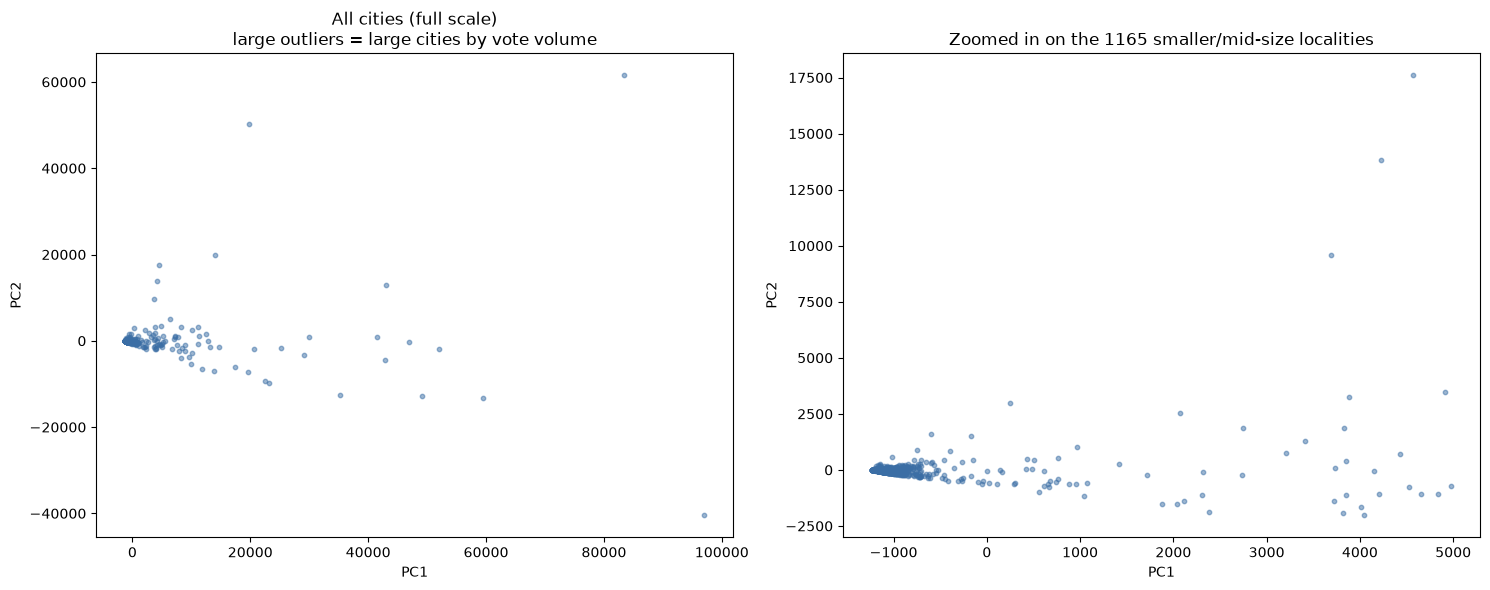

In [8]:
agg_real_cities = agg[agg["city_name"] != "מעטפות חיצוניות"].reset_index(drop=True)
city_data = remove_sparse_columns(agg_real_cities, threshold=1000)
reduced_cities = dimensionality_reduction(city_data, num_components=2, meta_columns=["city_name"])

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(reduced_cities["PC1"], reduced_cities["PC2"], s=10, alpha=0.5, color="#3b6ea5")
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].set_title("All cities (full scale)\nlarge outliers = large cities by vote volume")

zoomed = reduced_cities[reduced_cities["PC1"] < 5000]
axes[1].scatter(zoomed["PC1"], zoomed["PC2"], s=10, alpha=0.5, color="#3b6ea5")
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title(f"Zoomed in on the {len(zoomed)} smaller/mid-size localities")
plt.tight_layout()
plt.show()


**Interpretation — Compare Cities.** Because PCA here is run on raw (non-standardized)
vote *counts*, PC1 is dominated by each city's overall number of votes cast: Tel
Aviv-Yafo, Jerusalem, Haifa, Rishon LeZion and a handful of other big cities separate
out on the far right of the full-scale plot simply because their vote totals for every
party are large. Once we zoom in on the remaining ~1,165 small/mid-size localities, a
denser structure emerges: most towns sit in one large, fairly continuous blob (their
relative party preferences are broadly similar), with visually distinguishable
elongated arms/sub-groups branching off — these correspond to clusters of towns that
share a distinctive political profile (e.g. strongly religious localities pulling one
direction, strongly secular/Arab-sector localities pulling another). Overall we'd
estimate roughly **2–4 loose clusters** by eye, plus the handful of big-city outliers
that form clusters of their own by sheer scale.

### 5b. Compare Parties

Now we transpose so each row is a **party** and each column is a **city**, drop cities
with under 1,000 total votes, and run PCA again.

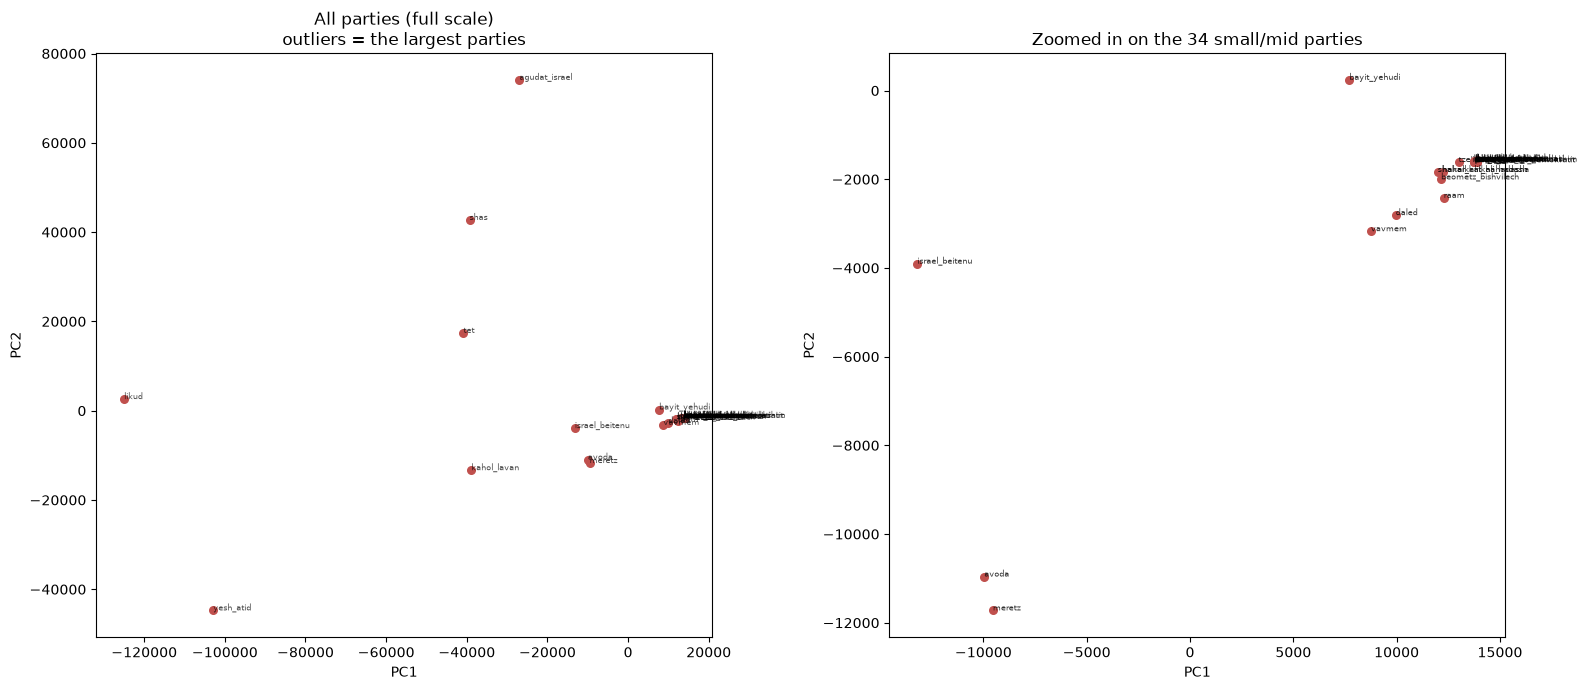

In [9]:
city_indexed = agg_real_cities.set_index("city_name")
party_wide = city_indexed.T
party_wide.index.name = "party_name"
party_wide_reset = party_wide.reset_index()

party_wide_filtered = remove_sparse_columns(party_wide_reset, threshold=1000)
reduced_parties = dimensionality_reduction(party_wide_filtered, num_components=2, meta_columns=["party_name"])

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
axes[0].scatter(reduced_parties["PC1"], reduced_parties["PC2"], s=30, color="#c0504d")
for _, row in reduced_parties.iterrows():
    axes[0].annotate(row["party_name"].replace("party_", ""), (row["PC1"], row["PC2"]), fontsize=6, alpha=0.7)
axes[0].set_xlabel("PC1"); axes[0].set_ylabel("PC2")
axes[0].set_title("All parties (full scale)\noutliers = the largest parties")

zoomed_p = reduced_parties[(reduced_parties["PC1"].abs() < 20000) & (reduced_parties["PC2"].abs() < 20000)]
axes[1].scatter(zoomed_p["PC1"], zoomed_p["PC2"], s=30, color="#c0504d")
for _, row in zoomed_p.iterrows():
    axes[1].annotate(row["party_name"].replace("party_", ""), (row["PC1"], row["PC2"]), fontsize=6, alpha=0.8)
axes[1].set_xlabel("PC1"); axes[1].set_ylabel("PC2")
axes[1].set_title(f"Zoomed in on the {len(zoomed_p)} small/mid parties")
plt.tight_layout()
plt.show()


**Interpretation — Compare Parties.** The same effect happens in reverse: parties with
huge nationwide vote totals — Likud and Yesh Atid especially, followed by Shas,
Kahol Lavan, Agudat Israel, and Tet (United Torah Judaism / Otzma-style lists depending
on labelling) — stand far apart from everyone else, again mostly because of raw vote
volume. Zooming in on the remaining small/mid parties, most of them cluster very
tightly together near the origin, because they all received a similarly small (and
similarly-shaped) trickle of votes across most cities. The parties that do separate
slightly from that main cluster in the zoomed view tend to be regionally-concentrated
lists (e.g. an Arab-sector party or a specific religious-sector list) that draw votes
from a narrower, distinct set of cities rather than everywhere. Very roughly, we'd
estimate **1 dominant big-party cluster of outliers + 1 large "minor party" cluster**,
with a couple of small parties as visually distinguishable near-outliers.

### 5c. Vote Distribution: Jerusalem vs. Tel Aviv-Yafo

Finally, we compare the (percentage) vote share of each party in Jerusalem and Tel
Aviv-Yafo directly with a bar chart, after removing parties with under 1,000 total
votes. We use each party's **share of the city's total votes** (rather than raw counts)
so the two cities — which have very different total vote counts — are comparable.

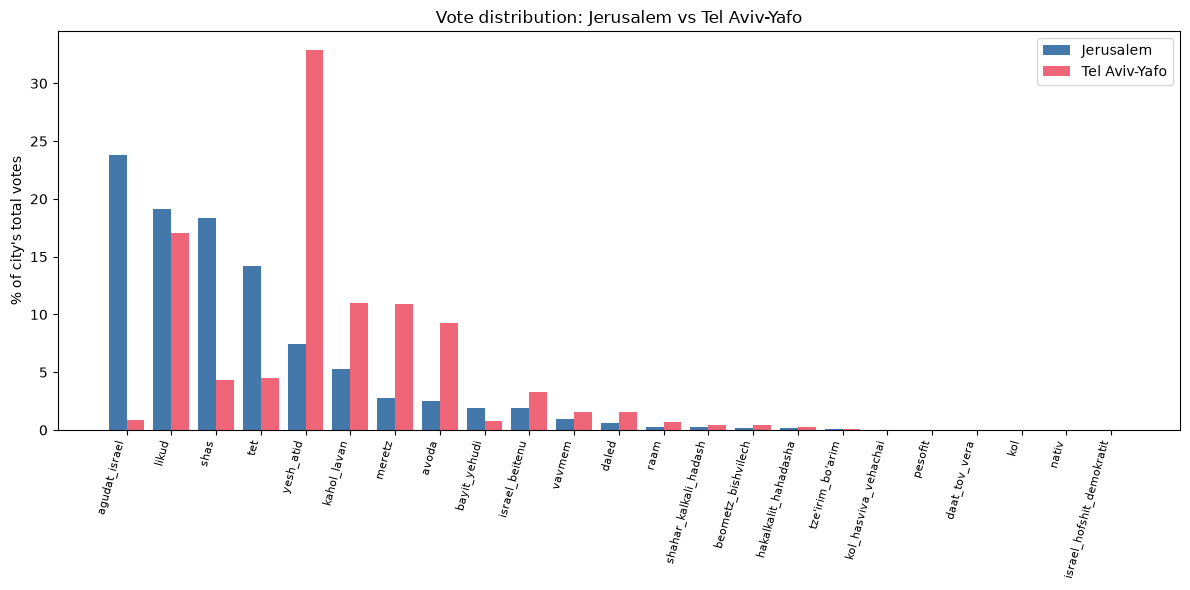

In [10]:
jt = city_data[city_data["city_name"].isin(["ירושלים", "תל אביב  יפו"])].set_index("city_name")
jt_pct = jt.div(jt.sum(axis=1), axis=0) * 100
jt_pct = jt_pct.T.sort_values(by="ירושלים", ascending=False)

fig, ax = plt.subplots(figsize=(12, 6))
x = np.arange(len(jt_pct))
width = 0.4
ax.bar(x - width / 2, jt_pct["ירושלים"], width, label="Jerusalem", color="#4477aa")
ax.bar(x + width / 2, jt_pct["תל אביב  יפו"], width, label="Tel Aviv-Yafo", color="#ee6677")
ax.set_xticks(x)
ax.set_xticklabels([c.replace("party_", "") for c in jt_pct.index], rotation=75, ha="right", fontsize=8)
ax.set_ylabel("% of city's total votes")
ax.set_title("Vote distribution: Jerusalem vs Tel Aviv-Yafo")
ax.legend()
plt.tight_layout()
plt.show()


**Interpretation — Jerusalem vs. Tel Aviv-Yafo.** The two cities show almost a mirror
image of each other. In Jerusalem, the religious parties (Agudat Israel ~24%, Shas
~18%, and the "Tet"-coded list ~14%) together with Likud (~19%) dominate, while
Yesh Atid takes only about 7–8%. In Tel Aviv-Yafo the pattern flips: Yesh Atid alone
takes roughly a third of the vote (~33%), with Kahol Lavan, Meretz and Avoda — the
more secular/center-left lists — each pulling meaningful double-digit-to-high-single-digit
shares, while Agudat Israel and Shas barely register (under 5% combined). What's
*similar* is that in both cities Likud pulls a broadly comparable share (~17–19%) —
it's the one party with genuinely cross-cutting appeal here. What's *different* is
everything downstream of that: Jerusalem's vote is concentrated in religious/
Haredi-aligned lists, while Tel Aviv-Yafo's vote is concentrated in secular, centrist
and left-leaning lists — reflecting the well-known religious/secular divide between the
two cities.

## Optional: Interactive Plotly Versions

The assignment suggests using **Plotly** instead of Matplotlib for interactive
hover-tooltips (and optionally 3D plots). The static charts above already show the
key results computed from the exact same `dimensionality_reduction` output, but if you
have `plotly` installed you can reproduce them interactively with the cells below
(hover over a point to see the city/party name).

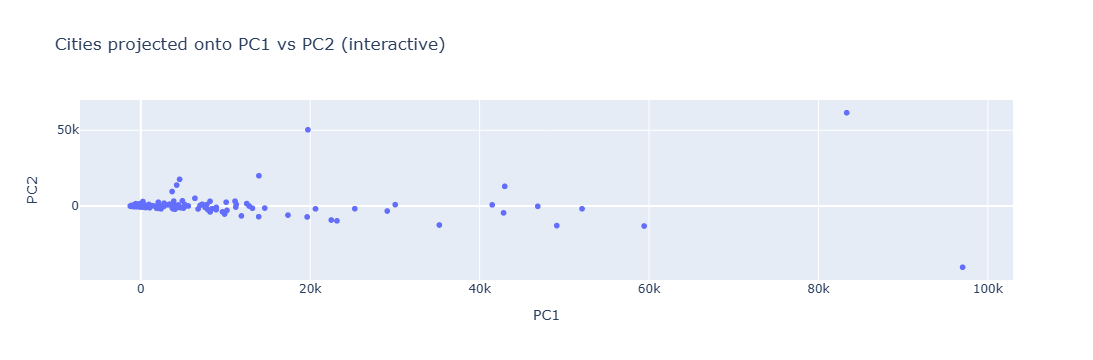

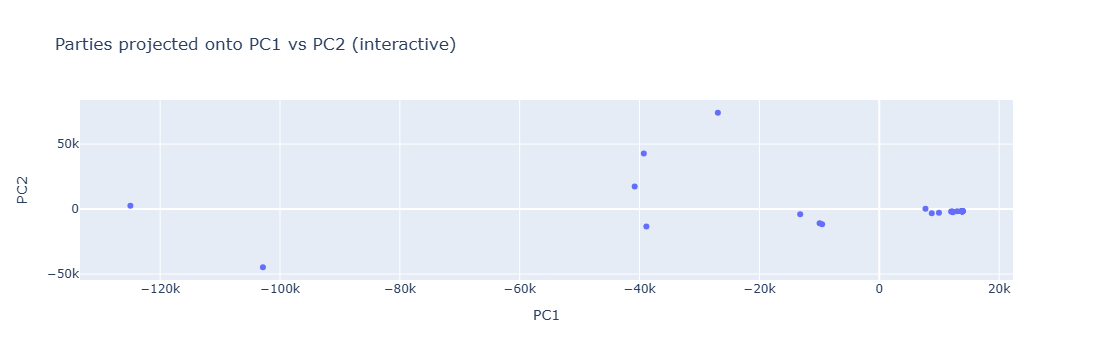

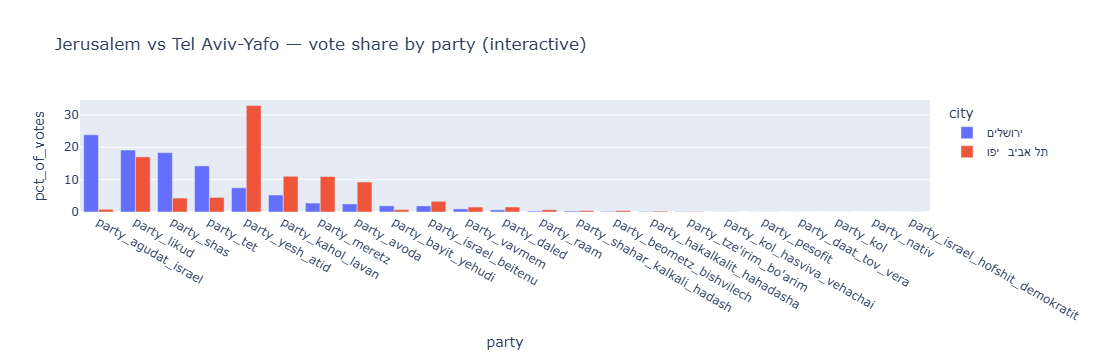

In [11]:
import plotly.express as px

fig = px.scatter(
    reduced_cities, x="PC1", y="PC2", hover_name="city_name",
    title="Cities projected onto PC1 vs PC2 (interactive)"
)
fig.show()

fig2 = px.scatter(
    reduced_parties, x="PC1", y="PC2", hover_name="party_name",
    title="Parties projected onto PC1 vs PC2 (interactive)"
)
fig2.show()

jt_long = jt_pct.reset_index().melt(id_vars="index", var_name="city", value_name="pct_of_votes")
jt_long = jt_long.rename(columns={"index": "party"})
fig3 = px.bar(
    jt_long, x="party", y="pct_of_votes", color="city", barmode="group",
    title="Jerusalem vs Tel Aviv-Yafo — vote share by party (interactive)"
)
fig3.show()
